# Read-only inspection cell (Step Zero)

In [1]:
import inspect
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import sparse

from digikala_review_transformer import (
    baseline,
    config,
    data_io,
    labels,
    metrics,
    utils,
)

proc, interim = Path(config.DATA_PROCESSED), Path(config.DATA_INTERIM)
reports, artifacts = Path(config.REPORTS), Path(config.ARTIFACTS)
train_csv = proc / "train_supervised.csv"

print("== config constants ==")
for name in sorted(n for n in dir(config) if n.isupper()):
    print(name, "=", getattr(config, name))

print("\n== train_supervised.csv header ==")
head_df = pd.read_csv(train_csv, nrows=3, dtype=str, keep_default_na=False)
print(head_df.columns.tolist())
print(head_df.drop(columns=["body"], errors="ignore").to_string())

print("\n== labels constants ==")
for name in ("CLASSES", "LABEL_COLS", "RAW_COL", "CORR_COL"):
    print(name, "=", getattr(labels, name, "MISSING"))

print("\n== signatures and docstrings ==")
for fn in (baseline.train_lr, baseline.load_cache, data_io.read_split,
           data_io.build_head_data, labels.encode, labels.class_weights,
           metrics.evaluate, utils.timer):
    print(f"{fn.__module__}.{fn.__name__}{inspect.signature(fn)}")
    print(inspect.getdoc(fn), "\n")

print("== source: baseline.train_lr ==")
print(inspect.getsource(baseline.train_lr))

print("== registry ==")
registry = pd.read_csv(reports / "model_registry.csv")
print(registry.to_string())

print("\n== final_fit selected rows ==")
final_fit = pd.read_csv(reports / "baseline_tfidf" / "tables" / "final_fit.csv")
cols = ["model_id", "C", "val_macro_f1", "n_iter", "converged", "fit_seconds", "max_iter"]
print(final_fit[final_fit["selected"].astype(str) == "True"][cols].to_string())

print("\n== config.json (read-only) ==")
cfg = json.loads((artifacts / "baseline_tfidf" / "config.json").read_text(encoding="utf-8"))
print(list(cfg))
print(json.dumps(cfg.get("final_settings"), indent=2, ensure_ascii=False))

print("\n== cache ids vs train_supervised ==")
ids_cache = pd.read_parquet(interim / "tfidf_cache" / "ids_tfidf12_train.parquet")
print(ids_cache.shape, ids_cache.columns.tolist())
use = [c for c in ("id", "product_id", "rate", "step1_rec_label", "step1_rate_band_label")
       if c in head_df.columns]
train_small = pd.read_csv(train_csv, usecols=use, dtype=str, keep_default_na=False)
print("rows:", len(train_small), "| unique id:", train_small["id"].nunique())
id_col = "id" if "id" in ids_cache.columns else ids_cache.columns[0]
print("ids column used:", id_col)
print("ids equal in order:", train_small["id"].tolist() == ids_cache[id_col].astype(str).tolist())
print("unique products:", train_small["product_id"].nunique())
for col in ("step1_rec_label", "step1_rate_band_label"):
    if col in train_small:
        print(col, train_small[col].value_counts(dropna=False).to_dict())
print("rate == 0:", (pd.to_numeric(train_small["rate"], errors="coerce") == 0).sum())

print("\n== cache matrix ==")
X_train = sparse.load_npz(interim / "tfidf_cache" / "X_tfidf12_train.npz").tocsr()
row_nnz = np.diff(X_train.indptr)
print(X_train.shape, X_train.dtype, "nnz:", X_train.nnz,
      "| zero-feature rows:", int((row_nnz == 0).sum()))

free_gb = shutil.disk_usage(config.ROOT).free / 1e9
print(f"\nfree disk: {free_gb:.1f} GB")

== config constants ==
ARTIFACTS = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/artifacts
CLEAN_TABLE = clean_base
DATA_INTERIM = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/interim
DATA_PROCESSED = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/processed
DATA_RAW = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/raw
DB_PATH = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/project.duckdb
MASK_RATE = 0.2
MASK_SEED = digikala-semi-supervised-v1
PSEUDO_LABEL_THRESHOLD = 0.9
REPORTS = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports
ROOT = /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer
SPLIT_SEED = 2026

== train_supervised.csv header ==
['id', 'body', 'product_id', 'recommendation_status', 'step1_rec_label', 'rating_band', 'step1_rate_ba

# Cell 1 — Imports

In [ ]:
# Cell 1 — Imports
%load_ext autoreload
%autoreload 2

# Standard library
import json
import os  # noqa: F401
import sys
import time
from pathlib import Path

# Third-party
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Image, display
from scipy import sparse

# Project modules (the notebook only calls functions from here)
# Note: `timer` is our own function in utils, never `import timer`
from digikala_review_transformer import (
    baseline,
    config,
    data_io,
    labels,
    metrics,
    plot_style,
    utils,
)

# Environment report: versions, interpreter path (needed later for the terminal command)
print("python      :", sys.version.split()[0])
print("interpreter :", sys.executable)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scipy       :", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

# Sanity check: project root and the two inputs this phase depends on
print("ROOT exists        :", Path(config.ROOT).is_dir())
print("train csv exists   :", (Path(config.DATA_PROCESSED) / "train_supervised.csv").is_file())
print("tfidf cache exists :", (Path(config.DATA_INTERIM) / "tfidf_cache").is_dir())

python      : 3.12.16
interpreter : /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/.venv/bin/python
numpy       : 2.5.4
pandas      : 3.1.1
scipy       : 1.18.1
scikit-learn: 1.9.1
ROOT exists        : True
train csv exists   : True
tfidf cache exists : True


# Cell 2 — Parameters

In [3]:
# Cell 2 — Parameters
# All constants of this phase live here.
# Paths come from config; C comes from model_registry.csv and LR settings come from the
# baseline config.json (both read in Cell 5). Nothing below duplicates those values.

# ---- Heads, label variant and reference models ----
HEADS = ("rec", "band")
VARIANT = "B"                      # corrected (Step 1) labels only, until the end of the project
MODEL_TAG = "tfidf12"              # tag of the cached TF-IDF matrices
REFERENCE_MODEL_IDS = {head: f"{MODEL_TAG}_{head}_{VARIANT}" for head in HEADS}
AMBIGUOUS_CLASS = {"rec": "no_idea", "band": "medium"}   # classes checked for the "ambiguity penalty"

# ---- Expected counts (verified in the read-only inspection; used only in asserts) ----
EXPECTED_TRAIN_ROWS = 2_860_236
EXPECTED_LABELED_ROWS = {"rec": 2_392_157, "band": 2_860_236}
EXPECTED_ZERO_FEATURE_ROWS = 3_724

# ---- Column names (corrected label columns come from labels.CORR_COL, not typed here) ----
ID_COL = "id"
PRODUCT_COL = "product_id"
RATE_COL = "rate"                  # analysis only, never a model feature

# ---- Folds (product-grouped OOF) ----
N_FOLDS = 5
FOLD_SEED = config.SPLIT_SEED      # one seed source for the whole project
FOLD_SHUFFLE = True

# ---- OOF script settings ----
OOF_N_JOBS = 1                     # 1 for the probe run; set after measuring time and RAM
OOF_BLAS_THREADS_PER_WORKER = 1    # avoids CPU oversubscription when workers run in parallel
PROBE_HEAD = "rec"                 # first run: one fold only, as a time/RAM probe
PROBE_FOLD = 0
PROB_SUM_TOL = 1e-5                # OOF probabilities must sum to 1 within this tolerance

# ---- Weight formula: w = max(W_MIN, 1 - C * (1 - Q)) ----
W_MIN = 0.1
ENTROPY_EPS = 1e-12                # lower clip inside log only; probabilities are not renormalized
ZERO_FEATURE_POLICY = "weight_one" # rows with 0 TF-IDF features: w = 1, excluded from class means m_c
assert ZERO_FEATURE_POLICY in ("weight_one",), "unknown ZERO_FEATURE_POLICY"

# ---- Quality thresholds (engineering guesses, NOT derived from data; they only print OK/WARN) ----
OOF_F1_MAX_ABOVE_VAL = 0.02        # OOF Macro F1 above reference validation by more -> possible leakage
OOF_F1_MAX_BELOW_VAL = 0.05        # OOF Macro F1 below reference validation by more -> possible bug
AMBIGUOUS_CLASS_MEAN_GAP_MAX = 0.05  # mean w of ambiguous class vs other classes (pooled) max gap
MEAN_WEIGHT_MIN = 0.85             # minimum overall mean of w
LOW_WEIGHT_CUTOFF = 0.3            # a row is "low weight" if w <= this
LOW_WEIGHT_SHARE_MAX = 0.10        # max allowed share of low-weight rows
HALF_WEIGHT_CUTOFF = 0.5           # extra summary column: share of rows with w < this
REVIEW_SUSPICIOUS_MIN_SHARE_LOW = 0.70             # low-w stratum: min share with verdict "ok"
REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH = 0.10   # high-w stratum: max share with verdict "too_high"

# ---- Weight tables ----
WEIGHT_QUANTILES = (0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99)

# ---- Manual review sample ----
REVIEW_N = 100
REVIEW_QUOTAS = {"high": 40, "mid": 30, "low": 30}   # strata by w_min = min(w_rec, w_band), NaN ignored
REVIEW_HIGH_MIN_W = 0.9            # "high" stratum: w >= this
REVIEW_LOW_MAX_W = 0.5             # "low" stratum: w < this; "mid" is in between
REVIEW_MIN_RATE_ZERO = 10          # at least this many rate == 0 rows, if available
REVIEW_SEED = config.SPLIT_SEED
REVIEW_VERDICT_VALUES = ("ok", "too_low", "too_high", "unsure")
assert sum(REVIEW_QUOTAS.values()) == REVIEW_N, "review quotas must sum to REVIEW_N"

# ---- Charts ----
SAMPLE_N_FOR_CHARTS = 200_000      # bounded sample for the Q-C density chart only
CHART_SAMPLE_SEED = config.SPLIT_SEED

# ---- Input paths ----
TRAIN_CSV = Path(config.DATA_PROCESSED) / "train_supervised.csv"
CACHE_DIR = Path(config.DATA_INTERIM) / "tfidf_cache"
X_TRAIN_NPZ = CACHE_DIR / f"X_{MODEL_TAG}_train.npz"
IDS_TRAIN_PARQUET = CACHE_DIR / f"ids_{MODEL_TAG}_train.parquet"
BASELINE_CONFIG_JSON = Path(config.ARTIFACTS) / "baseline_tfidf" / "config.json"
MODEL_REGISTRY_CSV = Path(config.REPORTS) / "model_registry.csv"
FINAL_FIT_CSV = Path(config.REPORTS) / "baseline_tfidf" / "tables" / "final_fit.csv"

# ---- Output paths (nothing is created in this cell) ----
STEP2_OOF_DIR = Path(config.DATA_INTERIM) / "step2_oof"
FOLDS_PARQUET = STEP2_OOF_DIR / "step2_folds.parquet"
PARAMS_JSON = STEP2_OOF_DIR / "step2_params.json"
WEIGHTS_PARQUET = Path(config.DATA_PROCESSED) / "step2_sample_weights.parquet"
WEIGHTS_ARTIFACT_DIR = Path(config.ARTIFACTS) / "step2_weighting"
WEIGHTS_CONFIG_JSON = WEIGHTS_ARTIFACT_DIR / "weights_config.json"
DECISION_JSON = WEIGHTS_ARTIFACT_DIR / "step2_decision.json"
STEP2_TABLES_DIR = Path(config.REPORTS) / "step2_weighting" / "tables"
STEP2_FIGURES_DIR = Path(config.REPORTS) / "step2_weighting" / "figures"
TIMING_CSV = STEP2_TABLES_DIR / "timing.csv"
MANUAL_REVIEW_CSV = STEP2_TABLES_DIR / "manual_review_sample.csv"
OOF_SCRIPT_PATH = Path(config.ROOT) / "scripts" / "step2_run_oof.py"

# ---- Quick checks: inputs exist, registry has the reference models ----
required_inputs = [TRAIN_CSV, X_TRAIN_NPZ, IDS_TRAIN_PARQUET, BASELINE_CONFIG_JSON,
                   MODEL_REGISTRY_CSV, FINAL_FIT_CSV]
missing_inputs = [str(path) for path in required_inputs if not path.is_file()]
assert not missing_inputs, f"missing input files: {missing_inputs}"

registry_check = pd.read_csv(MODEL_REGISTRY_CSV)
for head, model_id in REFERENCE_MODEL_IDS.items():
    registry_rows = registry_check[registry_check["model_id"] == model_id]
    assert len(registry_rows) == 1, f"{model_id}: expected exactly one registry row"
    print(f"{head:5s} -> {model_id} | C from registry = {registry_rows.iloc[0]['C']}")

print("heads:", HEADS, "| variant:", VARIANT, "| folds:", N_FOLDS, "| seed:", FOLD_SEED)
print("W_MIN:", W_MIN, "| ENTROPY_EPS:", ENTROPY_EPS, "| zero-feature policy:", ZERO_FEATURE_POLICY)
print("corrected label columns:", {head: labels.CORR_COL[head] for head in HEADS})

rec   -> tfidf12_rec_B | C from registry = 0.3
band  -> tfidf12_band_B | C from registry = 0.1
heads: ('rec', 'band') | variant: B | folds: 5 | seed: 2026
W_MIN: 0.1 | ENTROPY_EPS: 1e-12 | zero-feature policy: weight_one
corrected label columns: {'rec': 'step1_rec_label', 'band': 'step1_rate_band_label'}


# Cell 3 — Load Training Table and Cache


In [4]:
# Cell 3 — Load Training Table and Cache
from digikala_review_transformer import (
    sample_weights,  # new module (will move to Cell 1 later)
)

step_seconds = {}                                         # step name -> seconds (written to timing.csv in Cell 14)
start_time = time.perf_counter()

# ---- Load the training table: id, product_id, rate, y_rec, y_band (body dropped) ----
train_table = sample_weights.load_training_table(
    TRAIN_CSV, HEADS, id_col=ID_COL, product_col=PRODUCT_COL, rate_col=RATE_COL,
)

# ---- Zero-feature flags from the cached matrix (also asserts cache id order == table order) ----
zero_feature_mask, cache_info = sample_weights.zero_feature_flags(
    X_TRAIN_NPZ, IDS_TRAIN_PARQUET, train_table[ID_COL].to_numpy(), id_col=ID_COL,
)
train_table["n_features_zero"] = zero_feature_mask

# ---- Data-integrity checks: any failure stops the run (assert) ----
load_checks = sample_weights.build_load_checks(
    train_table, HEADS, EXPECTED_TRAIN_ROWS, EXPECTED_LABELED_ROWS, EXPECTED_ZERO_FEATURE_ROWS,
    id_col=ID_COL,
)
print(load_checks.to_string(index=False))
assert load_checks["ok"].all(), "load checks failed, see table above"
assert cache_info["n_rows"] == EXPECTED_TRAIN_ROWS, "cache matrix row count mismatch"

# ---- Information for the report (no asserts) ----
print("\ncache matrix:", cache_info)
print("unique products:", train_table[PRODUCT_COL].nunique())
print("rate: missing =", int(train_table[RATE_COL].isna().sum()),
      "| rate == 0 =", int((train_table[RATE_COL] == 0).sum()))

for head in HEADS:
    class_names = labels.CLASSES[head]
    counts = train_table[f"y_{head}"].value_counts().sort_index()
    print(f"\n{head} class counts (code: name = rows):")
    for code, class_name in enumerate(class_names):
        print(f"  {code}: {class_name} = {int(counts.get(code, 0)):,}")
    print(f"  unlabeled rows: {int(train_table[f'y_{head}'].isna().sum()):,}")

# ---- Zero-feature rows split by label availability (they stay in OOF, get w = 1 later) ----
zero_rows = train_table[train_table["n_features_zero"]]
print("\nzero-feature rows:", len(zero_rows),
      "| with rec label:", int(zero_rows["y_rec"].notna().sum()),
      "| with band label:", int(zero_rows["y_band"].notna().sum()))

step_seconds["cell3_load_training_table"] = time.perf_counter() - start_time
print(f"\nCell 3 finished in {step_seconds['cell3_load_training_table']:.1f} s")
print("train_table memory (MB):", round(train_table.memory_usage(deep=True).sum() / 1e6, 1))

              check     got  expected   ok
         train rows 2860236   2860236 True
         unique ids 2860236   2860236 True
 labeled rows (rec) 2392157   2392157 True
labeled rows (band) 2860236   2860236 True
  zero-feature rows    3724      3724 True

cache matrix: {'n_rows': 2860236, 'n_features': 500000, 'nnz': 57544256, 'dtype': 'float32'}
unique products: 209460
rate: missing = 0 | rate == 0 = 253509

rec class counts (code: name = rows):
  0: recommended = 1,834,524
  1: not_recommended = 266,638
  2: no_idea = 290,995
  unlabeled rows: 468,079

band class counts (code: name = rows):
  0: low = 549,788
  1: medium = 500,933
  2: high = 1,809,515
  unlabeled rows: 0

zero-feature rows: 3724 | with rec label: 2749 | with band label: 3724

Cell 3 finished in 5.7 s
train_table memory (MB): 125.1


# Cell 4 — Build Product-Grouped Folds

In [5]:
# Cell 4 — Build Product-Grouped Folds
start_time = time.perf_counter()
STEP2_OOF_DIR.mkdir(parents=True, exist_ok=True)
STEP2_TABLES_DIR.mkdir(parents=True, exist_ok=True)

fold_by_head = {}
check_frames = []
balance_frames = []

for head in HEADS:
    # Product-grouped, label-stratified folds for this head (sklearn warnings are not silenced)
    folds = sample_weights.build_group_folds(
        train_table, head, N_FOLDS, FOLD_SEED, shuffle=FOLD_SHUFFLE, product_col=PRODUCT_COL,
    )
    fold_by_head[head] = folds

    # Data-integrity checks for this head
    check_frames.append(
        sample_weights.check_folds(train_table, folds, head, N_FOLDS, product_col=PRODUCT_COL)
    )
    # Fold size and class distribution for this head
    balance_frames.append(
        sample_weights.fold_balance_table(train_table, folds, head, product_col=PRODUCT_COL)
    )

fold_checks = pd.concat(check_frames, ignore_index=True)
fold_balance = pd.concat(balance_frames, ignore_index=True)

# ---- Checks: any failure stops the run ----
print(fold_checks.to_string(index=False))
assert fold_checks["ok"].all(), "fold checks failed, see table above"

# ---- Fold balance (information for the report) ----
with pd.option_context("display.float_format", "{:.2f}".format, "display.width", 200):
    print()
    print(fold_balance.to_string(index=False))

# ---- Save: folds parquet (written once, compared if it exists) and balance table ----
folds_frame = sample_weights.make_folds_frame(train_table, fold_by_head, HEADS, id_col=ID_COL)
save_status = sample_weights.save_folds_once(folds_frame, FOLDS_PARQUET)
fold_balance.to_csv(STEP2_TABLES_DIR / "fold_balance.csv", index=False)

print("\nfolds parquet:", FOLDS_PARQUET.name, "|", save_status, "| shape:", folds_frame.shape)
print("fold_balance.csv saved to:", STEP2_TABLES_DIR)

step_seconds["cell4_build_folds"] = time.perf_counter() - start_time
print(f"Cell 4 finished in {step_seconds['cell4_build_folds']:.1f} s")

head                                           check             got        expected   ok
 rec                        labeled rows with a fold         2392157         2392157 True
 rec                      unlabeled rows with a fold               0               0 True
 rec                                   fold ids used [0, 1, 2, 3, 4] [0, 1, 2, 3, 4] True
 rec                  products in more than one fold               0               0 True
 rec (fold, class) cells with an empty training side               0               0 True
 rec        (fold, class) cells with no held-out row               0               0 True
band                        labeled rows with a fold         2860236         2860236 True
band                      unlabeled rows with a fold               0               0 True
band                                   fold ids used [0, 1, 2, 3, 4] [0, 1, 2, 3, 4] True
band                  products in more than one fold               0               0 True
band (fold

# Cell 5 — Write Params Snapshot and Launch OOF Script

In [6]:
# Cell 5 — Write Params Snapshot and Launch OOF Script
import shlex

start_time = time.perf_counter()
assert OOF_SCRIPT_PATH.is_file(), f"create the script first: {OOF_SCRIPT_PATH}"

# ---- Read the recipe from the baseline artifacts (nothing typed here) ----
registry = pd.read_csv(MODEL_REGISTRY_CSV)
baseline_config = json.loads(BASELINE_CONFIG_JSON.read_text(encoding="utf-8"))
lr_settings = baseline_config["final_settings"]

head_settings = {}
for head in HEADS:
    model_id = REFERENCE_MODEL_IDS[head]
    registry_row = registry[registry["model_id"] == model_id].iloc[0]
    # The registry row must describe the corrected-label model with the expected row count
    assert registry_row["train_label_col"] == labels.CORR_COL[head], f"{model_id}: wrong label column"
    assert int(registry_row["n_train_rows"]) == EXPECTED_LABELED_ROWS[head], f"{model_id}: row count differs"
    assert registry_row["class_weight"] == lr_settings["class_weight"], f"{model_id}: class_weight differs"
    head_settings[head] = {
        "C": float(registry_row["C"]),
        "label_col": labels.CORR_COL[head],
        "class_names": list(labels.CLASSES[head]),
        "registry_model_id": model_id,
        "n_labeled_rows": int(train_table[f"y_{head}"].notna().sum()),
    }

# ---- Build the snapshot ----
params_snapshot = {
    "written_by": "notebook 09, cell 5",
    "model_tag": MODEL_TAG, "variant": VARIANT,
    "n_folds": N_FOLDS, "fold_seed": FOLD_SEED,
    "n_jobs": OOF_N_JOBS, "blas_threads_per_worker": OOF_BLAS_THREADS_PER_WORKER,
    "prob_sum_tol": PROB_SUM_TOL,
    "id_col": ID_COL, "head_names": list(HEADS),
    "x_train_npz": str(X_TRAIN_NPZ), "ids_train_parquet": str(IDS_TRAIN_PARQUET),
    "folds_parquet": str(FOLDS_PARQUET), "folds_sha256": utils.sha256_file(FOLDS_PARQUET),
    "oof_dir": str(STEP2_OOF_DIR),
    "lr": {"solver": lr_settings["solver"], "tol": lr_settings["tol"],
           "max_iter": lr_settings["max_iter_final"], "class_weight": lr_settings["class_weight"]},
    "heads": head_settings,
}

# ---- If a snapshot exists, report whether the result-affecting fields changed (n_jobs may change) ----
if PARAMS_JSON.exists():
    old_snapshot = json.loads(PARAMS_JSON.read_text(encoding="utf-8"))
    ignored_keys = {"n_jobs"}
    changed_keys = [key for key in params_snapshot
                    if key not in ignored_keys and old_snapshot.get(key) != params_snapshot[key]]
    print("existing snapshot found | result-affecting keys changed:", changed_keys or "none")
utils.write_json(params_snapshot, PARAMS_JSON)

print("\nparams snapshot:", PARAMS_JSON)
print("LR settings   :", params_snapshot["lr"])
for head, settings in head_settings.items():
    print(f"{head:5s} C={settings['C']} | label col={settings['label_col']} | labeled rows={settings['n_labeled_rows']:,}")
print("folds sha256  :", params_snapshot["folds_sha256"])

# ---- Status of OOF files ----
done_files = sorted(path.name for path in STEP2_OOF_DIR.glob("oof_*_meta.json"))
print("\nfold meta files already present:", done_files if done_files else "none")

# ---- Terminal command for the probe: one fold only, one worker ----
probe_command = (
    f"cd {shlex.quote(str(config.ROOT))} && "
    f"{shlex.quote(sys.executable)} {shlex.quote(str(OOF_SCRIPT_PATH.relative_to(config.ROOT)))} "
    f"--params {shlex.quote(str(PARAMS_JSON))} --heads {PROBE_HEAD} --folds {PROBE_FOLD} --n-jobs 1 "
    f"2>&1 | tee -a {shlex.quote(str(STEP2_OOF_DIR / 'oof_run.log'))}"
)
print("\n=== run this in a terminal (NOT in Jupyter) ===")
print(probe_command)

step_seconds["cell5_params_snapshot"] = time.perf_counter() - start_time


params snapshot: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/interim/step2_oof/step2_params.json
LR settings   : {'solver': 'lbfgs', 'tol': 0.0001, 'max_iter': 1000, 'class_weight': 'balanced'}
rec   C=0.3 | label col=step1_rec_label | labeled rows=2,392,157
band  C=0.1 | label col=step1_rate_band_label | labeled rows=2,860,236
folds sha256  : f4ba6fa2fcc2178f69ebcf8b65b6375731cb878f2dc1bbee62b03823bf85b60e

fold meta files already present: none

=== run this in a terminal (NOT in Jupyter) ===
cd /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer && /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/.venv/bin/python scripts/step2_run_oof.py --params /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/interim/step2_oof/step2_params.json --heads rec --folds 0 --n-jobs 1 2>&1 | tee -a /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transf

# Cell 6 — Assemble OOF Probabilities

In [7]:
# Cell 6 — Assemble OOF Probabilities
start_time = time.perf_counter()

# ---- Fold meta files: all 10 must exist and match the current recipe ----
fold_meta = sample_weights.load_fold_meta(STEP2_OOF_DIR, HEADS, N_FOLDS)
labeled_counts = {head: int(train_table[f"y_{head}"].notna().sum()) for head in HEADS}
meta_checks = sample_weights.check_fold_meta(fold_meta, params_snapshot, labeled_counts)
print(meta_checks.to_string(index=False))
assert meta_checks["ok"].all(), "fold meta checks failed, see table above"

# Convergence is reported, never silenced
print("\nnon-converged fits:", int((~fold_meta["converged"]).sum()), "of", len(fold_meta))

# ---- Assemble per head, with coverage / alignment / probability assertions ----
oof_by_head = {}
info_rows = []
for head in HEADS:
    oof_table, oof_info = sample_weights.assemble_oof(
        train_table, fold_by_head[head], head, STEP2_OOF_DIR, N_FOLDS,
        id_col=ID_COL, prob_sum_tol=PROB_SUM_TOL,
    )
    oof_by_head[head] = oof_table
    info_rows.append(oof_info)

    # Save once (compared if it exists)
    oof_path = STEP2_OOF_DIR / f"oof_probs_{head}.parquet"
    save_status = sample_weights.save_parquet_once(oof_table, oof_path)
    print(f"\n{head}: {oof_path.name} | {save_status} | shape: {oof_table.shape}")

print()
print(pd.DataFrame(info_rows).to_string(index=False))

# ---- Information for the report: mean OOF probability per class vs the true class share ----
for head in HEADS:
    prob_columns = [f"p_{name}" for name in labels.CLASSES[head]]
    labeled_codes = train_table[f"y_{head}"].dropna().astype("int8")
    true_share = labeled_codes.value_counts(normalize=True).sort_index().to_numpy()
    mean_prob = oof_by_head[head][prob_columns].mean().to_numpy()
    print(f"\n{head}: class | true share | mean OOF probability")
    for name, share, prob in zip(labels.CLASSES[head], true_share, mean_prob):
        print(f"  {name:16s} {share:.4f} | {prob:.4f}")

step_seconds["cell6_assemble_oof"] = time.perf_counter() - start_time
print(f"\nCell 6 finished in {step_seconds['cell6_assemble_oof']:.1f} s")

head                          check                                                              got                                                         expected   ok
 rec               distinct recipes                                                                1                                                                1 True
 rec                       recipe C                                                              0.3                                                              0.3 True
 rec            recipe label column                                                  step1_rec_label                                                  step1_rec_label True
 rec            recipe class_weight                                                         balanced                                                         balanced True
 rec                  recipe solver                                                            lbfgs                                             

# Cell 7 — OOF Sanity Checks

In [8]:
# Cell 7 — OOF Sanity Checks
start_time = time.perf_counter()

# ── Reference: validation scores of the selected baseline fits (B models) ──
reference_scores = sample_weights.reference_validation_scores(FINAL_FIT_CSV, REFERENCE_MODEL_IDS)
print(reference_scores.to_string())

# The reference row must be the same model recipe we used for OOF (same C)
for head in HEADS:
    assert np.isclose(reference_scores.loc[head, "C"], params_snapshot["heads"][head]["C"]), \
        f"{head}: reference C differs from the C used in OOF"

# ── OOF scores against the corrected label: overall and per fold ──
sanity_frames = []
for head in HEADS:
    sanity_frames.append(sample_weights.oof_sanity_table(
        train_table, oof_by_head[head], head, fold_meta,
        reference_f1=reference_scores.loc[head, "val_macro_f1"],
        max_above=OOF_F1_MAX_ABOVE_VAL, max_below=OOF_F1_MAX_BELOW_VAL, id_col=ID_COL,
    ))
oof_sanity = pd.concat(sanity_frames, ignore_index=True)

print()
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 220):
    print(oof_sanity.to_string(index=False))

# ── Spread of Macro F1 across folds (information only) ──
print()
for head in HEADS:
    fold_f1 = oof_sanity[(oof_sanity["head"] == head) & (oof_sanity["scope"] != "all")]["macro_f1"]
    print(f"{head}: fold Macro F1 min {fold_f1.min():.4f} | max {fold_f1.max():.4f} | "
          f"spread {fold_f1.max() - fold_f1.min():.4f}")

# ── Dtype of the saved probabilities (checks my float32 explanation) ──
for head in HEADS:
    prob_columns = [f"p_{name}" for name in labels.CLASSES[head]]
    print(f"{head}: probability dtypes in OOF parquet:",
          sorted({str(dtype) for dtype in oof_by_head[head][prob_columns].dtypes}))

# ── Acceptance status of this check (prints only, never stops the run) ──
print("\nOOF vs validation reference (thresholds are engineering guesses, not derived from data):")
for _, row in oof_sanity[oof_sanity["scope"] == "all"].iterrows():
    print(f"  {row['head']:5s} {row['status']:11s} | OOF {row['macro_f1']:.4f} | "
          f"reference {row['reference_val_macro_f1']:.4f} | diff {row['f1_minus_reference']:+.4f} | "
          f"allowed: +{OOF_F1_MAX_ABOVE_VAL} / -{OOF_F1_MAX_BELOW_VAL}")

# ── Save ──
oof_sanity.to_csv(STEP2_TABLES_DIR / "oof_sanity.csv", index=False)
print("\nsaved:", STEP2_TABLES_DIR / "oof_sanity.csv")

step_seconds["cell7_oof_sanity"] = time.perf_counter() - start_time
print(f"Cell 7 finished in {step_seconds['cell7_oof_sanity']:.1f} s")

            model_id    C  val_macro_f1  val_accuracy
rec    tfidf12_rec_B  0.3      0.687386      0.816943
band  tfidf12_band_B  0.1      0.583427      0.674585

head scope  n_rows  macro_f1  accuracy  reference_val_macro_f1  f1_minus_reference status  n_iter  converged  fit_seconds
 rec   all 2392157    0.6767    0.7897                  0.6874             -0.0107     OK     279       True     562.7000
 rec     0  478431    0.6772    0.7897                  0.6874             -0.0102      -     240       True      87.6000
 rec     1  478431    0.6759    0.7894                  0.6874             -0.0115      -     279       True     136.7000
 rec     2  478431    0.6764    0.7891                  0.6874             -0.0110      -     233       True     113.4000
 rec     3  478431    0.6777    0.7908                  0.6874             -0.0097      -     214       True     107.4000
 rec     4  478433    0.6762    0.7895                  0.6874             -0.0112      -     256       T

# Cell 8 — Compute Q, C and Weights

In [9]:
# Cell 8 — Compute Q, C and Weights
start_time = time.perf_counter()

# ── Local parameters of this cell ──
ZERO_COL = "n_features_zero"       # column created in Cell 3
HAND_CHECK_N = 2_000               # rows recomputed one by one with plain python
HAND_CHECK_TOL = 1e-6              # float32 storage error is ~6e-8, so this is generous
HAND_CHECK_SEED = config.SPLIT_SEED

# ── Compute p_y, Q, C and w for each head ──
arrays_by_head, info_by_head = {}, {}
for head in HEADS:
    arrays_by_head[head], info_by_head[head] = sample_weights.compute_head_weights(
        train_table, oof_by_head[head], head,
        w_min=W_MIN, eps=ENTROPY_EPS, zero_policy=ZERO_FEATURE_POLICY,
        prob_tol=PROB_SUM_TOL, id_col=ID_COL, zero_col=ZERO_COL,
    )

# ── Assemble the weights table (id, flag, then p_y / q / c / w per head) ──
weights_frame = sample_weights.build_weights_frame(
    train_table, arrays_by_head, HEADS, id_col=ID_COL, zero_col=ZERO_COL,
)

# ── Data-integrity checks: print only failures plus one summary line ──
weight_checks = sample_weights.check_weights(
    weights_frame, train_table, HEADS, W_MIN, id_col=ID_COL, zero_col=ZERO_COL,
)
failed_checks = weight_checks[~weight_checks["ok"]]
if len(failed_checks):
    print(failed_checks.to_string(index=False))
print(f"weight checks: {int(weight_checks['ok'].sum())} of {len(weight_checks)} OK")
assert weight_checks["ok"].all(), "weight checks failed, see table above"

# ── Independent hand check of the formula on random rows ──
for head in HEADS:
    max_difference = sample_weights.verify_weights_by_hand(
        train_table, oof_by_head[head], weights_frame, head,
        class_means=info_by_head[head]["class_means"], w_min=W_MIN, eps=ENTROPY_EPS,
        n_sample=HAND_CHECK_N, seed=HAND_CHECK_SEED, id_col=ID_COL, zero_col=ZERO_COL,
    )
    print(f"{head:5s} hand check on {HAND_CHECK_N:,} rows | max |difference| = {max_difference:.2e}")
    assert max_difference <= HAND_CHECK_TOL, f"{head}: hand check failed"

# ── Class means m_c (recorded for the report and for weights_config.json) ──
print("\nclass means m_c (mean OOF p_y of the recorded class, zero-feature rows excluded):")
for head in HEADS:
    info = info_by_head[head]
    for name, mean_value, n_rows in zip(info["class_names"], info["class_means"], info["class_rows_used"]):
        print(f"  {head:5s} {name:16s} m_c = {mean_value:.4f} | rows used = {n_rows:,}")

# ── Diagnostics for the report (information only) ──
print("\ndiagnostics:")
for head in HEADS:
    info = info_by_head[head]
    print(f"  {head:5s} labeled = {info['n_labeled']:,} | zero-feature labeled = {info['n_zero_feature_labeled']:,} | "
          f"probs below eps = {info['n_probs_below_eps']} | "
          f"C raw range = [{info['c_raw_min']:.2e}, {info['c_raw_max']:.4f}]")
    print(f"        share Q capped at 1 = {info['share_q_capped_at_1']:.3f} | "
          f"share w at W_MIN = {info['share_w_at_floor']:.4f} | mean w = {info['mean_w']:.4f}")

# ── Save once (compared with the existing file if it exists) ──
save_status = sample_weights.save_parquet_once(weights_frame, WEIGHTS_PARQUET)
print(f"\n{WEIGHTS_PARQUET.name} | {save_status} | shape: {weights_frame.shape}")
print("columns:", weights_frame.columns.tolist())

step_seconds["cell8_compute_weights"] = time.perf_counter() - start_time
print(f"Cell 8 finished in {step_seconds['cell8_compute_weights']:.1f} s")

weight checks: 31 of 31 OK
rec   hand check on 2,000 rows | max |difference| = 2.97e-08
band  hand check on 2,000 rows | max |difference| = 2.98e-08

class means m_c (mean OOF p_y of the recorded class, zero-feature rows excluded):
  rec   recommended      m_c = 0.7205 | rows used = 1,832,352
  rec   not_recommended  m_c = 0.6581 | rows used = 266,317
  rec   no_idea          m_c = 0.5084 | rows used = 290,739
  band  low              m_c = 0.4777 | rows used = 549,127
  band  medium           m_c = 0.4317 | rows used = 500,431
  band  high             m_c = 0.4978 | rows used = 1,806,954

diagnostics:
  rec   labeled = 2,392,157 | zero-feature labeled = 2,749 | probs below eps = 0 | C raw range = [8.37e-07, 1.0000]
        share Q capped at 1 = 0.596 | share w at W_MIN = 0.0006 | mean w = 0.9603
  band  labeled = 2,860,236 | zero-feature labeled = 3,724 | probs below eps = 0 | C raw range = [1.32e-07, 0.9964]
        share Q capped at 1 = 0.489 | share w at W_MIN = 0.0001 | mean w = 0

# Cell 9: Weight Summary and Acceptance Status

## requirement data, info

In [ ]:
# ── Read-only inspection before Cell 9 (no state is changed) ──
import inspect

import pandas as pd

# Columns and dtypes of the training table kept in the kernel
print("train_table shape:", train_table.shape)
print(train_table.dtypes.to_string())
print(train_table.head(2).to_string())

# Names of all DataFrames currently alive in the kernel
print("\nDataFrames in kernel:",
      [name for name, obj in globals().items()
       if isinstance(obj, pd.DataFrame) and not name.startswith("_")])

# Signatures of the weight functions and the public names of the labels module
print("\nbuild_weights_frame:", inspect.signature(sample_weights.build_weights_frame))
print("compute_head_weights:", inspect.signature(sample_weights.compute_head_weights))
print("labels module names:", [n for n in dir(sample_weights.labels) if not n.startswith("_")])

train_table shape: (2860236, 6)
id                     str
product_id             str
rate               float64
y_rec                 Int8
y_band                Int8
n_features_zero       bool
         id product_id  rate  y_rec  y_band  n_features_zero
0  53672599     252058   1.0      1       0            False
1   9897229     252058   0.0      0       0            False

DataFrames in kernel: ['head_df', 'registry', 'final_fit', 'ids_cache', 'train_small', 'registry_check', 'registry_rows', 'train_table', 'load_checks', 'zero_rows', 'fold_checks', 'fold_balance', 'folds_frame', 'fold_meta', 'meta_checks', 'oof_table', 'reference_scores', 'oof_sanity', 'weights_frame', 'weight_checks', 'failed_checks']

build_weights_frame: (table, arrays_by_head, heads, id_col='id', zero_col='n_features_zero')
compute_head_weights: (table, oof, head, w_min, eps, zero_policy, prob_tol, id_col='id', zero_col='n_features_zero')
labels module names: ['CLASSES', 'CORR_COL', 'LABEL_COLS', 'RAW_COL', 'ann

## Cell 9, itself

In [11]:
# ── Cell 9: Weight Summary and Acceptance Status ──
# Builds the per-class weight tables, the w quantiles and the OK/WARN acceptance status.
# Thresholds only warn, they never stop the run (they are engineering guesses, not data-derived).
import importlib
import time
from pathlib import Path

importlib.reload(sample_weights)
cell_start = time.perf_counter()

# ── Local parameters ──
# Class names in label-code order (0, 1, 2) as defined by the project label maps
CLASS_NAMES_BY_HEAD = {
    "rec":  ("recommended", "not_recommended", "no_idea"),
    "band": ("low", "medium", "high"),
}
RATE_SPLIT_HEADS = ("band",)
WEIGHT_SUMMARY_CSV = Path(STEP2_TABLES_DIR) / "weight_summary.csv"
WEIGHT_QUANTILES_CSV = Path(STEP2_TABLES_DIR) / "weight_quantiles.csv"
ACCEPTANCE_STATUS_CSV = Path(STEP2_TABLES_DIR) / "acceptance_status.csv"

for head in HEADS:
    assert AMBIGUOUS_CLASS[head] in CLASS_NAMES_BY_HEAD[head]

# ── Per-head views of the labeled rows ──
views_by_head = {
    head: sample_weights.head_weight_view(train_table, weights_frame, head, CLASS_NAMES_BY_HEAD[head])
    for head in HEADS
}
for head, view in views_by_head.items():
    assert len(view) == EXPECTED_LABELED_ROWS[head], f"{head}: labeled row count mismatch"

# ── Tables ──
summary_table = sample_weights.weight_summary_table(
    views_by_head, CLASS_NAMES_BY_HEAD, LOW_WEIGHT_CUTOFF, HALF_WEIGHT_CUTOFF, RATE_SPLIT_HEADS)
quantile_table = sample_weights.weight_quantile_table(
    views_by_head, CLASS_NAMES_BY_HEAD, WEIGHT_QUANTILES)
status_table = sample_weights.acceptance_status_table(
    views_by_head, AMBIGUOUS_CLASS, MEAN_WEIGHT_MIN,
    LOW_WEIGHT_CUTOFF, LOW_WEIGHT_SHARE_MAX, AMBIGUOUS_CLASS_MEAN_GAP_MAX)

# ── Save (each file is written once) ──
save_results = {
    path.name: sample_weights.save_table_once(table, path)
    for table, path in [(summary_table, WEIGHT_SUMMARY_CSV),
                        (quantile_table, WEIGHT_QUANTILES_CSV),
                        (status_table, ACCEPTANCE_STATUS_CSV)]
}

# ── Print ──
fmt = lambda value: f"{value:.4f}"
print("── weight summary (w: all labeled rows | p_y, q, c: zero-feature rows excluded) ──")
print(summary_table.to_string(index=False, float_format=fmt))
print("\n── w quantiles, all rows per head ──")
print(quantile_table[quantile_table["group"] == "ALL"].to_string(index=False, float_format=fmt))
print("\n── acceptance status (OK / WARN, informational only) ──")
print(status_table.to_string(index=False, float_format=fmt))
print("\nfiles:", save_results)
print(f"Cell 9 finished in {time.perf_counter() - cell_start:.1f} s")

── weight summary (w: all labeled rows | p_y, q, c: zero-feature rows excluded) ──
head        split            group   count  mean_w  median_w  share_w_le_low  share_w_lt_half  mean_p_y  mean_q  mean_c
 rec          all              ALL 2392157  0.9603    1.0000          0.0031           0.0104    0.6877  0.8416  0.4825
 rec        class      recommended 1834524  0.9646    1.0000          0.0014           0.0068    0.7205  0.8466  0.5176
 rec        class  not_recommended  266638  0.9623    1.0000          0.0033           0.0088    0.6581  0.8320  0.4384
 rec        class          no_idea  290995  0.9314    1.0000          0.0142           0.0352    0.5084  0.8191  0.3016
band          all              ALL 2860236  0.9781    0.9997          0.0006           0.0026    0.4823  0.8293  0.1684
band        class              low  549788  0.9679    0.9984          0.0004           0.0026    0.4777  0.7790  0.2313
band        class           medium  500933  0.9687    0.9994          0.0015 

# Cell 10: Manual Review Sample

In [17]:
# ── Cell 10: Manual Review Sample ──
# Draws the 100-row review sample (stratified by w_min) and writes the CSV for manual verdicts.
# An existing review file is never overwritten, so verdicts already entered are safe.
import importlib
import time
from pathlib import Path

import pandas as pd

importlib.reload(sample_weights)
cell_start = time.perf_counter()

# ── Local parameters ──
BODY_COL = "body"
REVIEW_LOW_PER_HEAD = REVIEW_QUOTAS["low"] // 2     # low stratum is split evenly between the two heads
assert 2 * REVIEW_LOW_PER_HEAD == REVIEW_QUOTAS["low"]
assert sum(REVIEW_QUOTAS.values()) == REVIEW_N

# ── Pool: weights + corrected labels + rate (row order is identical, checked by id) ──
assert train_table[ID_COL].equals(weights_frame[ID_COL])
assert train_table.index.equals(weights_frame.index)
pool = weights_frame.assign(rate=train_table[RATE_COL],
                            y_rec=train_table["y_rec"],
                            y_band=train_table["y_band"])

# ── Attach the review text (id and body only; ids are read as strings) ──
texts = pd.read_csv(TRAIN_CSV, usecols=[ID_COL, BODY_COL], dtype={ID_COL: "str"})
pool = sample_weights.attach_body(pool, texts, ID_COL, BODY_COL)
del texts

# ── Eligible rows: no zero-feature, no blank body, one random row per unique body ──
pool, pool_counts = sample_weights.eligible_review_pool(pool, REVIEW_SEED, ZERO_COL, BODY_COL)
pool = sample_weights.assign_review_stratum(pool, REVIEW_HIGH_MIN_W, REVIEW_LOW_MAX_W)

# ── Draw, check, build the review file ──
picked = sample_weights.draw_review_rows(
    pool, REVIEW_QUOTAS, REVIEW_LOW_MAX_W, REVIEW_MIN_RATE_ZERO, REVIEW_SEED)
sample = pool.iloc[picked].sample(frac=1.0, random_state=REVIEW_SEED).reset_index(drop=True)

review_checks = sample_weights.check_review_sample(
    sample, REVIEW_QUOTAS, REVIEW_HIGH_MIN_W, REVIEW_LOW_MAX_W,
    REVIEW_MIN_RATE_ZERO, REVIEW_LOW_PER_HEAD, ID_COL, BODY_COL, ZERO_COL)
failed_review_checks = review_checks[~review_checks["passed"]]
print(f"review checks: {int(review_checks['passed'].sum())} of {len(review_checks)} OK")
if len(failed_review_checks):
    print(failed_review_checks.to_string(index=False))
assert failed_review_checks.empty, "review sample integrity check failed"

review_table = sample_weights.build_review_frame(sample, CLASS_NAMES_BY_HEAD, ID_COL, BODY_COL, RATE_COL)
write_status = sample_weights.write_review_file_once(review_table, MANUAL_REVIEW_CSV, ID_COL)

# ── Summary ──
print("\npool:", pool_counts)
print("stratum counts:", sample["stratum"].value_counts().to_dict())
print("w_min range per stratum:")
print(sample.groupby("stratum")["w_min"].agg(["min", "max"]).round(4).to_string())
print(f"\nrows with rate==0: {int((sample['rate'] == 0).sum())}"
      f" | rows with a rec label: {int(sample['y_rec'].notna().sum())}"
      f" | w_rec < {REVIEW_LOW_MAX_W}: {int((sample['w_rec'] < REVIEW_LOW_MAX_W).sum())}"
      f" | w_band < {REVIEW_LOW_MAX_W}: {int((sample['w_band'] < REVIEW_LOW_MAX_W).sum())}")
print(f"\nreview file: {MANUAL_REVIEW_CSV} -> {write_status}")
print(f"Cell 10 finished in {time.perf_counter() - cell_start:.1f} s")

review checks: 12 of 12 OK

pool: {'pool_rows': 2860236, 'after_zero_and_blank_filters': 2856512, 'unique_bodies': 2368882}
stratum counts: {'high': 40, 'mid': 30, 'low': 30}
w_min range per stratum:
            min     max
stratum                
high     0.9289  1.0000
low      0.1000  0.4983
mid      0.5281  0.8832

rows with rate==0: 18 | rows with a rec label: 91 | w_rec < 0.5: 21 | w_band < 0.5: 15

review file: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/step2_weighting/tables/manual_review_sample.csv -> written
Cell 10 finished in 11.9 s


# Cell 11: Review Verdicts and Decision

In [ ]:
# ── Cell 11: Decision Record (qualitative review, no row-level verdicts) ──
# Records the keep/drop decision. The manual review was qualitative: row-level verdicts were not
# entered, so the two review thresholds are written as NOT_EVALUATED instead of OK/WARN.
import importlib
import time

importlib.reload(sample_weights)
cell_start = time.perf_counter()

# ── Local parameters ──
DECISION = "keep"          # "keep": use the weights in the transformer | "drop": transformer runs with w=1
DECISION_NOTE = (
    "Qualitative manual review of the 100-row sample (no row-level verdicts recorded). "
    "Observation: the weights correct several clearly contradictory labels; wrong weights were mostly "
    "on ambiguous texts or on opinions that depend on personal interpretation. "
    "Decision: test the weights on the transformer against a w=1 run with identical settings and seed."
)
assert DECISION in ("keep", "drop")
assert len(review_table) == REVIEW_N

# ── Decision payload ──
decision_payload = {
    "decision": DECISION,
    "decided_by": "user",
    "note": DECISION_NOTE,
    "review_type": "qualitative",
    "review_sample_rows": len(review_table),
    "review_sample_file": Path(MANUAL_REVIEW_CSV).name,
    "row_level_verdicts_recorded": False,
    "review_thresholds": {
        "REVIEW_SUSPICIOUS_MIN_SHARE_LOW": {"value": REVIEW_SUSPICIOUS_MIN_SHARE_LOW, "status": "NOT_EVALUATED"},
        "REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH": {"value": REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH,
                                                      "status": "NOT_EVALUATED"},
    },
    "acceptance_status_file": ACCEPTANCE_STATUS_CSV.name,
    "thresholds_are_engineering_guesses": True,
}

# ── Save (written once; identical re-run is a no-op) ──
decision_status = sample_weights.write_json_once(decision_payload, DECISION_JSON)

# ── Print ──
print("decision:", DECISION, "->", decision_status, "|", DECISION_JSON)
print("review type: qualitative | row-level verdicts recorded: False")
print("review thresholds: NOT_EVALUATED (both)")
print(f"Cell 11 finished in {time.perf_counter() - cell_start:.1f} s")

decision: keep -> written | /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/artifacts/step2_weighting/step2_decision.json
review type: qualitative | row-level verdicts recorded: False
review thresholds: NOT_EVALUATED (both)
Cell 11 finished in 0.0 s


# Chart 01: Distribution of weights

## Cell 12a: Chart 01, Weight Distribution

fonts: Poppins + Vazirmatn
chart: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/step2_weighting/figures/01_weight_distribution.png | pixels: (3200, 1800) | size MB: 5.4
  rec: {'n': 2392157, 'n_below_one': 965516, 'mean_w': 0.960279, 'median_w': 1.0, 'share_w_le_low': 0.003147, 'share_w_lt_half': 0.010444, 'share_w_eq_one': 0.596383}
  band: {'n': 2860236, 'n_below_one': 1460602, 'mean_w': 0.978055, 'median_w': 0.999672, 'share_w_le_low': 0.000574, 'share_w_lt_half': 0.002553, 'share_w_eq_one': 0.489342}
cross-check with weight_summary: OK


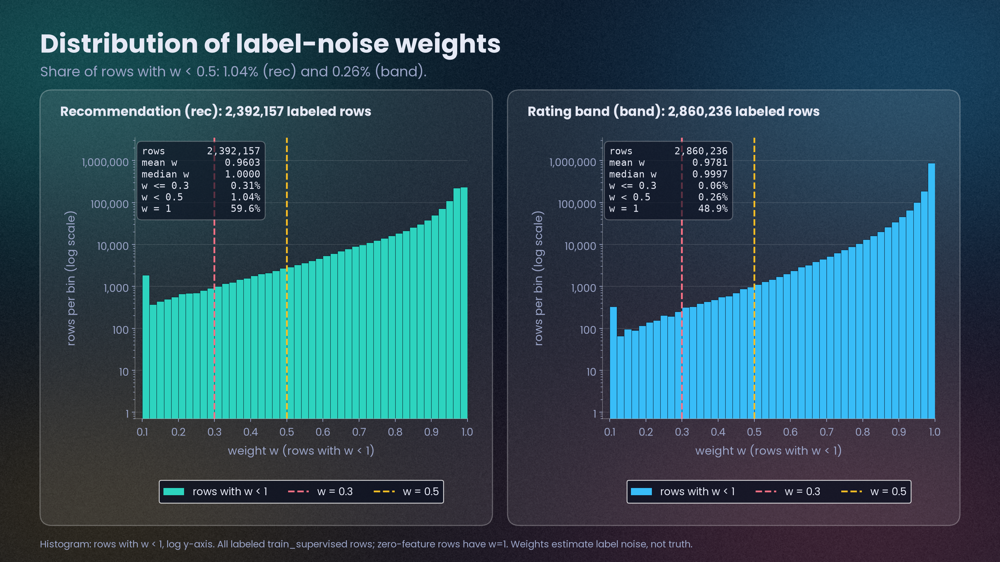

Cell 12a finished in 1.9 s


In [ ]:
# ── Cell 12a: Chart 01 — Weight Distribution ──
# Draws the weight histograms (rec | band), cross-checks the numbers on the chart against
# weight_summary, and saves 01_weight_distribution.png.
import importlib
import time
from pathlib import Path

import numpy as np
from IPython.display import Image, display  # noqa: F811

from digikala_review_transformer import plots_step2

importlib.reload(plots_step2)
cell_start = time.perf_counter()

# ── Local parameters ──
PLOT_FONT_DIR = Path(config.ROOT) / "assets" / "fonts"
CHART01_N_BINS = 45                      # bin width = (1 - W_MIN) / 45 = 0.02
style_info = plot_style.init_style(PLOT_FONT_DIR)

# ── Draw and save ──
chart_info = plots_step2.chart_01_weight_distribution(
    views_by_head, Path(STEP2_FIGURES_DIR), HEADS, W_MIN,
    LOW_WEIGHT_CUTOFF, HALF_WEIGHT_CUTOFF, CHART01_N_BINS)

# ── Cross-check: numbers on the chart vs the Cell 9 summary table ──
for head in HEADS:
    table_row = summary_table[(summary_table["head"] == head) & (summary_table["split"] == "all")].iloc[0]
    chart_row = chart_info["heads"][head]
    assert chart_row["n"] == table_row["count"], f"{head}: row count differs"
    for chart_key, table_key in [("mean_w", "mean_w"), ("median_w", "median_w"),
                                 ("share_w_le_low", "share_w_le_low"), ("share_w_lt_half", "share_w_lt_half")]:
        assert np.isclose(chart_row[chart_key], table_row[table_key], atol=1e-5), \
            f"{head}: {chart_key} differs between chart and summary table"

# ── Print and show ──
print("fonts:", style_info["english_font"], "+", style_info["persian_font"])
print("chart:", chart_info["path"], "| pixels:", chart_info["pixels"], "| size MB:", chart_info["size_mb"])
for head, values in chart_info["heads"].items():
    print(f"  {head}: {values}")
print("cross-check with weight_summary: OK")
display(Image(filename=chart_info["path"], width=1100))
print(f"Cell 12a finished in {time.perf_counter() - cell_start:.1f} s")

## Cell 12b: Chart 02, Class Weight Tails

chart: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/step2_weighting/figures/02_class_weight_tails.png | pixels: (3200, 1800) | size MB: 6.68
  rec: ambiguous gap = -0.0329
  band: ambiguous gap = -0.0114
cross-check with weight_summary and acceptance_status: OK


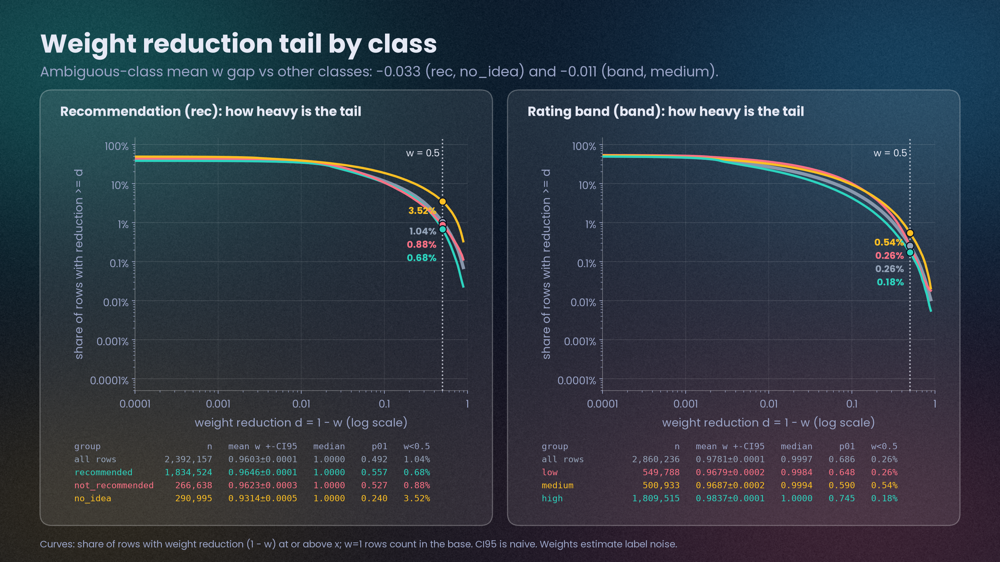

Cell 12b finished in 2.4 s


In [26]:
# ── Cell 12b: Chart 02 — Class Weight Tails ──
# Draws the per-class survival curves of 1 - w (rec | band), cross-checks every number on the chart
# against weight_summary and acceptance_status, and saves 02_class_weight_tails.png.
import importlib
import time
from pathlib import Path

import numpy as np
from IPython.display import Image, display

from digikala_review_transformer import plots_step2

importlib.reload(plots_step2)
cell_start = time.perf_counter()

# ── Local parameters ──
CHART02_X_MIN = 1e-4                     # smallest weight reduction shown on the log x-axis
CHART02_N_POINTS = 240
plot_style.init_style(Path(config.ROOT) / "assets" / "fonts")      # idempotent

# ── Draw and save ──
chart_info = plots_step2.chart_02_class_weight_tails(
    views_by_head, CLASS_NAMES_BY_HEAD, AMBIGUOUS_CLASS, Path(STEP2_FIGURES_DIR),
    HEADS, HALF_WEIGHT_CUTOFF, CHART02_X_MIN, CHART02_N_POINTS)

# ── Cross-check 1: chart statistics vs the Cell 9 summary table (all rows and every class) ──
for head in HEADS:
    for label, chart_row in chart_info["heads"][head]["groups"].items():
        split, group = ("all", "ALL") if label == "all rows" else ("class", label)
        table_row = summary_table[(summary_table["head"] == head) & (summary_table["split"] == split)
                                  & (summary_table["group"] == group)].iloc[0]
        assert chart_row["n"] == table_row["count"], f"{head}/{label}: row count differs"
        for key in ("mean_w", "median_w", "share_w_lt_half"):
            assert np.isclose(chart_row[key], table_row[key], atol=1e-5), f"{head}/{label}: {key} differs"

# ── Cross-check 2: ambiguous-class gap vs the Cell 9 acceptance status ──
for head in HEADS:
    status_row = status_table[(status_table["head"] == head)
                              & status_table["check"].str.startswith("ambiguous_gap")].iloc[0]
    assert np.isclose(chart_info["heads"][head]["ambiguous_gap"], status_row["value"], atol=1e-5), \
        f"{head}: ambiguous gap differs from acceptance_status"

# ── Print and show ──
print("chart:", chart_info["path"], "| pixels:", chart_info["pixels"], "| size MB:", chart_info["size_mb"])
for head in HEADS:
    print(f"  {head}: ambiguous gap = {chart_info['heads'][head]['ambiguous_gap']:+.4f}")
print("cross-check with weight_summary and acceptance_status: OK")
display(Image(filename=chart_info["path"], width=1100))
print(f"Cell 12b finished in {time.perf_counter() - cell_start:.1f} s")

## Cell 12c: Chart 03, Q–C Map

chart: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/step2_weighting/figures/03_q_c_map.png | pixels: (3200, 1800) | size MB: 6.13
  rec: sample 200,000 of 2,389,408 rows with Q and C | share Q=1: all rows 0.5959, sample 0.5937 | Spearman(Q, C) sample +0.701
  band: sample 200,000 of 2,856,512 rows with Q and C | share Q=1: all rows 0.4887, sample 0.4913 | Spearman(Q, C) sample +0.441
cross-check with weight_summary: OK | stored w follows w = max(W_MIN, 1 - C(1 - Q)) on the sample: OK


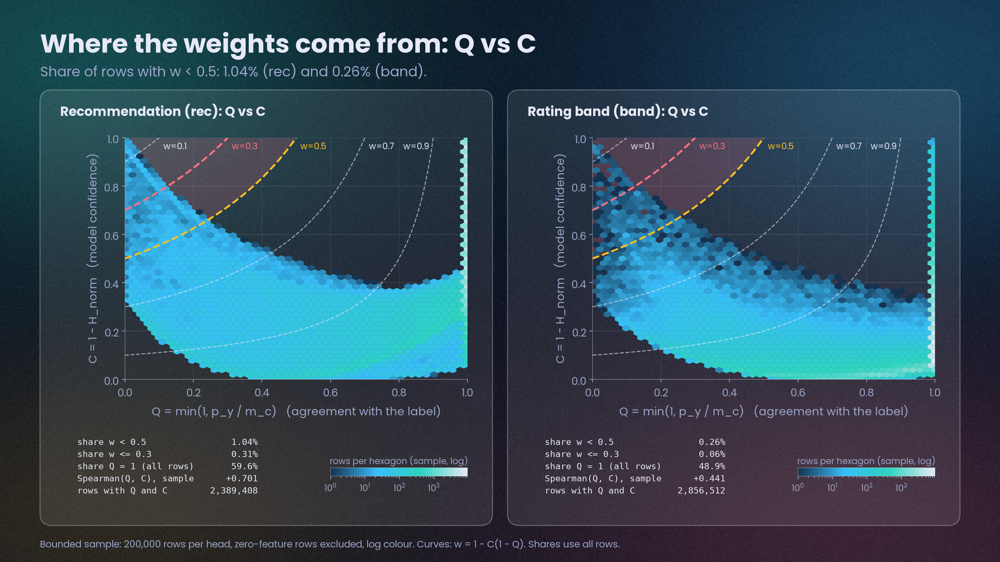

Cell 12c finished in 2.1 s


In [27]:
# ── Cell 12c: Chart 03 — Q vs C Map ──
# Draws the Q-C density maps with iso-weight curves from a bounded random sample, cross-checks the
# full-data shares against weight_summary, and saves 03_q_c_map.png.
import importlib
import time
from pathlib import Path

import numpy as np
from IPython.display import Image, display

from digikala_review_transformer import plots_step2

importlib.reload(plots_step2)
cell_start = time.perf_counter()

# ── Local parameters ──
CHART03_ISO_WEIGHTS = (0.9, 0.7, 0.5, 0.3, 0.1)       # includes HALF_WEIGHT_CUTOFF and LOW_WEIGHT_CUTOFF
CHART03_GRIDSIZE = 46                                  # hexagons along the x-axis
plot_style.init_style(Path(config.ROOT) / "assets" / "fonts")      # idempotent

# ── Draw and save ──
chart_info = plots_step2.chart_03_q_c_map(
    views_by_head, Path(STEP2_FIGURES_DIR), HEADS, W_MIN, LOW_WEIGHT_CUTOFF, HALF_WEIGHT_CUTOFF,
    CHART03_ISO_WEIGHTS, SAMPLE_N_FOR_CHARTS, CHART_SAMPLE_SEED, CHART03_GRIDSIZE)

# ── Cross-check: shares on the chart (all rows) vs the Cell 9 summary table ──
for head in HEADS:
    table_row = summary_table[(summary_table["head"] == head) & (summary_table["split"] == "all")].iloc[0]
    chart_row = chart_info["heads"][head]
    assert chart_row["n_labeled"] == table_row["count"], f"{head}: row count differs"
    for key in ("share_w_lt_half", "share_w_le_low"):
        assert np.isclose(chart_row[key], table_row[key], atol=1e-5), f"{head}: {key} differs"

# ── Print and show ──
print("chart:", chart_info["path"], "| pixels:", chart_info["pixels"], "| size MB:", chart_info["size_mb"])
for head in HEADS:
    row = chart_info["heads"][head]
    print(f"  {head}: sample {row['n_sample']:,} of {row['n_with_qc']:,} rows with Q and C"
          f" | share Q=1: all rows {row['share_q_one_full']:.4f}, sample {row['share_q_one_sample']:.4f}"
          f" | Spearman(Q, C) sample {row['spearman_q_c_sample']:+.3f}")
print("cross-check with weight_summary: OK | stored w follows w = max(W_MIN, 1 - C(1 - Q)) on the sample: OK")
display(Image(filename=chart_info["path"], width=1100))
print(f"Cell 12c finished in {time.perf_counter() - cell_start:.1f} s")

# Cell 13: Weighting Config and Artifact Checksums

In [32]:
# ── Cell 13: Weighting Config and Artifact Checksums ──
# Validates the saved weights, OOF recipes, class statistics, and review record,
# then writes a reproducible config with SHA-256 checksums.
import hashlib
import json
import math
import sys
import time
from collections.abc import Mapping
from importlib import metadata
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

cell_start = time.perf_counter()
root_path = Path(config.ROOT).resolve()
weights_path = Path(WEIGHTS_PARQUET).resolve()
ZERO_FEATURE_COL = "n_features_zero"
WEIGHT_COMPONENTS = ("p_y", "q", "c", "w")


# ── Helpers ──
# ── Cell 13 helper: convert nested Python and NumPy values to JSON-safe values ──
def _to_json_native(value):
    """Convert nested Python and NumPy values into finite, JSON-safe values."""
    if isinstance(value, Path):
        return value.as_posix()
    if isinstance(value, Mapping):
        return {str(key): _to_json_native(item) for key, item in value.items()}
    if isinstance(value, np.ndarray):
        return _to_json_native(value.tolist())
    if isinstance(value, (list, tuple)):
        return [_to_json_native(item) for item in value]
    if isinstance(value, np.generic):
        return _to_json_native(value.item())
    if isinstance(value, bool) or value is None or isinstance(value, (str, int)):
        return value
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError(f"non-finite float cannot be stored in JSON: {value}")
        return value
    raise TypeError(f"unsupported JSON value type: {type(value).__name__}")


def _sha256_file(path, chunk_size=8 * 1024 * 1024):
    """Calculate a file checksum without loading the whole file into memory."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _parse_fold_recipe(value):
    """Parse a fold recipe stored as JSON text or as a mapping."""
    if isinstance(value, str):
        parsed = json.loads(value)
    elif isinstance(value, Mapping):
        parsed = dict(value)
    else:
        raise TypeError(f"unsupported fold recipe type: {type(value).__name__}")
    if not isinstance(parsed, dict):
        raise TypeError("fold recipe must decode to a JSON object")
    return parsed


def _ordered_class_statistics(info, expected_class_names, head):
    """Map ordered class means and counts to names after validating the class order."""
    expected_names = tuple(expected_class_names)
    actual_names = tuple(str(name) for name in info["class_names"])
    if actual_names != expected_names:
        raise AssertionError(
            f"{head}: class order differs; expected {expected_names}, got {actual_names}"
        )

    means = np.asarray(info["class_means"], dtype="float64")
    row_counts = np.asarray(info["class_rows_used"], dtype="float64")
    expected_shape = (len(expected_names),)

    if means.shape != expected_shape or not np.isfinite(means).all():
        raise AssertionError(f"{head}: invalid class_means: {info['class_means']!r}")
    if row_counts.shape != expected_shape or not np.isfinite(row_counts).all():
        raise AssertionError(f"{head}: invalid class_rows_used: {info['class_rows_used']!r}")
    if (row_counts < 0).any() or not np.equal(row_counts, np.floor(row_counts)).all():
        raise AssertionError(f"{head}: class row counts must be non-negative integers")
    if not ((means > 0.0) & (means <= 1.0)).all():
        raise AssertionError(f"{head}: class means must be in (0, 1]")

    class_means = {
        class_name: float(mean_value)
        for class_name, mean_value in zip(expected_names, means)
    }
    class_rows_used = {
        class_name: int(row_count)
        for class_name, row_count in zip(expected_names, row_counts)
    }
    return class_means, class_rows_used


def _artifact_record(name, path):
    """Return a root-relative artifact record with size and SHA-256."""
    path = Path(path).resolve()
    if not path.is_file():
        raise FileNotFoundError(f"required artifact is missing: {path}")
    try:
        relative_path = path.relative_to(root_path).as_posix()
    except ValueError as error:
        raise AssertionError(f"artifact is outside the project root: {path}") from error

    return {
        "name": name,
        "path": relative_path,
        "size_bytes": int(path.stat().st_size),
        "sha256": _sha256_file(path),
    }


# ── Validate the in-memory table and saved weights parquet ──
expected_weight_columns = [ID_COL, ZERO_FEATURE_COL] + [
    f"{component}_{head}"
    for head in HEADS
    for component in WEIGHT_COMPONENTS
]

assert len(train_table) == EXPECTED_TRAIN_ROWS, "training table row count mismatch"
assert len(weights_frame) == EXPECTED_TRAIN_ROWS, "in-memory weights row count mismatch"
assert list(weights_frame.columns) == expected_weight_columns, (
    f"unexpected in-memory weight columns: {list(weights_frame.columns)}"
)
assert train_table[ID_COL].is_unique, "duplicate ids in the training table"
assert weights_frame[ID_COL].is_unique, "duplicate ids in the in-memory weights"
assert train_table[ID_COL].equals(weights_frame[ID_COL]), "training table and weights are not id-aligned"
assert np.array_equal(
    train_table[ZERO_FEATURE_COL].to_numpy(dtype=bool),
    weights_frame[ZERO_FEATURE_COL].to_numpy(dtype=bool),
), "zero-feature flags differ between the training table and weights"
assert int(train_table[ZERO_FEATURE_COL].sum()) == int(EXPECTED_ZERO_FEATURE_ROWS), (
    "zero-feature row count mismatch"
)

assert weights_path.is_file(), f"weights parquet is missing: {weights_path}"
parquet_file = pq.ParquetFile(weights_path)
assert parquet_file.metadata.num_rows == EXPECTED_TRAIN_ROWS, "weights parquet row count mismatch"
assert parquet_file.schema_arrow.names == expected_weight_columns, "weights parquet schema mismatch"


# ── Verify the saved OOF parameter snapshot and fold assignments ──
params_on_disk = json.loads(Path(PARAMS_JSON).read_text(encoding="utf-8"))
snapshot_keys = (
    "model_tag",
    "variant",
    "n_folds",
    "fold_seed",
    "n_jobs",
    "blas_threads_per_worker",
    "prob_sum_tol",
)
for key in snapshot_keys:
    assert key in params_snapshot and key in params_on_disk, f"missing parameter snapshot key: {key}"
    assert params_snapshot[key] == params_on_disk[key], f"parameter snapshot mismatch: {key}"

assert params_on_disk["model_tag"] == MODEL_TAG
assert params_on_disk["variant"] == VARIANT
assert int(params_on_disk["n_folds"]) == int(N_FOLDS)
assert int(params_on_disk["fold_seed"]) == int(FOLD_SEED)
assert int(params_on_disk["n_jobs"]) == int(OOF_N_JOBS)
assert np.isclose(
    float(params_on_disk["prob_sum_tol"]), float(PROB_SUM_TOL), rtol=0.0, atol=1e-15
)
folds_sha256 = _sha256_file(FOLDS_PARQUET)


# ── Validate OOF fold recipes and collect class and fit statistics ──
assert len(fold_meta) == len(HEADS) * N_FOLDS, "unexpected number of OOF fold records"
assert set(fold_meta["head"].astype(str)) == set(HEADS), "unexpected heads in fold metadata"
assert set(head_settings) == set(HEADS)
assert set(info_by_head) == set(HEADS)

head_config = {}
oof_fit_summary = {}

for head in HEADS:
    head_folds = fold_meta.loc[fold_meta["head"].astype(str) == head].copy()
    assert len(head_folds) == N_FOLDS, f"{head}: expected {N_FOLDS} fold records"

    fold_ids = pd.to_numeric(head_folds["fold"], errors="raise").to_numpy(dtype="int64")
    assert set(fold_ids) == set(range(N_FOLDS)), f"{head}: fold ids mismatch"

    converged_values = head_folds["converged"].tolist()
    all_converged = all(
        isinstance(value, (bool, np.bool_)) and bool(value)
        for value in converged_values
    )
    assert all_converged, f"{head}: one or more folds did not converge"

    recipes = [_parse_fold_recipe(value) for value in head_folds["recipe"]]
    recipe_signatures = {
        json.dumps(_to_json_native(recipe), sort_keys=True, separators=(",", ":"))
        for recipe in recipes
    }
    assert len(recipe_signatures) == 1, f"{head}: fold recipes differ"

    recipe = recipes[0]
    required_recipe_keys = {
        "model_tag", "label_col", "C", "class_weight", "solver",
        "tol", "max_iter", "folds_sha256",
    }
    assert required_recipe_keys.issubset(recipe), (
        f"{head}: fold recipe is missing keys "
        f"{sorted(required_recipe_keys - set(recipe))}"
    )
    assert recipe["folds_sha256"] == folds_sha256, f"{head}: fold-file checksum differs from recipe"

    settings = head_settings[head]
    class_names = tuple(CLASS_NAMES_BY_HEAD[head])
    assert tuple(settings["class_names"]) == class_names, f"{head}: class-name mapping differs"
    assert int(settings["n_labeled_rows"]) == int(EXPECTED_LABELED_ROWS[head])
    assert recipe["model_tag"] == MODEL_TAG
    assert recipe["label_col"] == settings["label_col"]
    assert np.isclose(float(recipe["C"]), float(settings["C"]), rtol=0.0, atol=1e-12)
    assert recipe["solver"] == lr_settings["solver"]
    assert recipe["class_weight"] == lr_settings["class_weight"]

    recipe_tol = float(recipe["tol"])
    recipe_max_iter = int(recipe["max_iter"])
    assert recipe_tol > 0.0, f"{head}: invalid tolerance in fold recipe"
    assert recipe_max_iter > 0, f"{head}: invalid max_iter in fold recipe"

    # ── Validate ordered class statistics against the corrected training labels ──
    info = info_by_head[head]
    class_means, class_rows_used = _ordered_class_statistics(info, class_names, head)

    labels = train_table[f"y_{head}"]
    zero_feature_mask = train_table[ZERO_FEATURE_COL].to_numpy(dtype=bool)
    labeled_mask = labels.notna().to_numpy()
    zero_feature_labeled = int((labeled_mask & zero_feature_mask).sum())

    assert int(info["n_labeled"]) == int(EXPECTED_LABELED_ROWS[head])
    assert int(info["n_zero_feature_labeled"]) == zero_feature_labeled

    eligible_labels = labels.loc[labeled_mask & ~zero_feature_mask].astype("int64")
    eligible_codes = eligible_labels.to_numpy(dtype="int64")
    assert np.isin(eligible_codes, np.arange(len(class_names))).all(), (
        f"{head}: invalid corrected class code"
    )
    observed_class_counts = (
        eligible_labels.value_counts()
        .reindex(range(len(class_names)), fill_value=0)
        .to_numpy(dtype="int64")
    )
    stored_class_counts = np.asarray(
        [class_rows_used[class_name] for class_name in class_names],
        dtype="int64",
    )
    assert np.array_equal(stored_class_counts, observed_class_counts), (
        f"{head}: class_rows_used do not match labeled non-zero-feature rows"
    )
    assert int(stored_class_counts.sum()) == (
        int(EXPECTED_LABELED_ROWS[head]) - zero_feature_labeled
    ), f"{head}: m_c row counts do not match the labeled non-zero-feature row count"

    head_config[head] = {
        "registry_model_id": str(settings["registry_model_id"]),
        "corrected_label_column": str(settings["label_col"]),
        "class_names_by_code": list(class_names),
        "n_labeled_rows": int(EXPECTED_LABELED_ROWS[head]),
        "n_zero_feature_labeled_rows": zero_feature_labeled,
        "C": float(recipe["C"]),
        "class_weight": recipe["class_weight"],
        "solver": recipe["solver"],
        "tol": recipe_tol,
        "max_iter": recipe_max_iter,
        "m_c": {
            class_name: {
                "mean_p_y": class_means[class_name],
                "rows_used": class_rows_used[class_name],
            }
            for class_name in class_names
        },
    }

    fit_seconds = pd.to_numeric(head_folds["fit_seconds"], errors="raise").to_numpy(
        dtype="float64"
    )
    n_iter_values = pd.to_numeric(head_folds["n_iter"], errors="raise").to_numpy(
        dtype="float64"
    )
    peak_rss_mb = pd.to_numeric(head_folds["peak_rss_mb"], errors="raise").to_numpy(
        dtype="float64"
    )

    assert np.isfinite(fit_seconds).all() and (fit_seconds > 0).all(), (
        f"{head}: invalid fit times"
    )
    assert np.isfinite(n_iter_values).all() and (n_iter_values > 0).all(), (
        f"{head}: invalid iteration counts"
    )
    assert np.equal(n_iter_values, np.floor(n_iter_values)).all(), (
        f"{head}: iteration counts must be integers"
    )
    assert (n_iter_values <= recipe_max_iter).all(), f"{head}: n_iter exceeds max_iter"
    assert np.isfinite(peak_rss_mb).all() and (peak_rss_mb > 0).all(), (
        f"{head}: invalid peak RSS values"
    )

    n_iter = n_iter_values.astype("int64")
    oof_fit_summary[head] = {
        "folds": int(len(head_folds)),
        "all_converged": True,
        "fit_seconds_per_fold": {
            "min": float(fit_seconds.min()),
            "median": float(np.median(fit_seconds)),
            "max": float(fit_seconds.max()),
        },
        "n_iter_range": [int(n_iter.min()), int(n_iter.max())],
        "max_worker_peak_rss_mb": float(peak_rss_mb.max()),
    }


# ── Validate the qualitative manual-review record ──
decision_doc = json.loads(Path(DECISION_JSON).read_text(encoding="utf-8"))
assert decision_doc["decision"] == "keep"
assert decision_doc["review_type"] == "qualitative"
assert decision_doc["row_level_verdicts_recorded"] is False
assert int(decision_doc["review_sample_rows"]) == int(REVIEW_N)
assert decision_doc["thresholds_are_engineering_guesses"] is True

review_check = pd.read_csv(
    MANUAL_REVIEW_CSV,
    usecols=[ID_COL, "verdict_rec", "verdict_band"],
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)
assert len(review_check) == int(REVIEW_N), "manual-review sample row count mismatch"
assert review_check[ID_COL].is_unique, "duplicate ids in manual-review sample"

verdicts_are_empty = review_check[["verdict_rec", "verdict_band"]].apply(
    lambda column: column.str.strip().eq("").all()
)
assert bool(verdicts_are_empty.all()), (
    "manual-review CSV contains verdicts but the decision record says none were recorded"
)

for threshold_name in (
    "REVIEW_SUSPICIOUS_MIN_SHARE_LOW",
    "REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH",
):
    assert decision_doc["review_thresholds"][threshold_name]["status"] == "NOT_EVALUATED"


# ── Hash the OOF outputs, reports, figures, and source files ──
artifact_specs = [
    ("sample_weights_parquet", WEIGHTS_PARQUET),
    ("fold_assignments", FOLDS_PARQUET),
    ("oof_parameter_snapshot", PARAMS_JSON),
    ("oof_probabilities_rec", Path(STEP2_OOF_DIR) / "oof_probs_rec.parquet"),
    ("oof_probabilities_band", Path(STEP2_OOF_DIR) / "oof_probs_band.parquet"),
    ("oof_run_log", Path(STEP2_OOF_DIR) / "oof_run.log"),
    ("oof_sanity_table", Path(STEP2_TABLES_DIR) / "oof_sanity.csv"),
    ("fold_balance_table", Path(STEP2_TABLES_DIR) / "fold_balance.csv"),
    ("weight_summary_table", Path(STEP2_TABLES_DIR) / "weight_summary.csv"),
    ("weight_quantiles_table", Path(STEP2_TABLES_DIR) / "weight_quantiles.csv"),
    ("weight_acceptance_table", Path(STEP2_TABLES_DIR) / "acceptance_status.csv"),
    ("manual_review_sample", MANUAL_REVIEW_CSV),
    ("decision_record", DECISION_JSON),
    ("figure_01_weight_distribution", Path(STEP2_FIGURES_DIR) / "01_weight_distribution.png"),
    ("figure_02_class_weight_tails", Path(STEP2_FIGURES_DIR) / "02_class_weight_tails.png"),
    ("figure_03_q_c_map", Path(STEP2_FIGURES_DIR) / "03_q_c_map.png"),
    ("oof_runner_script", OOF_SCRIPT_PATH),
    ("weighting_module", Path(sample_weights.__file__)),
    (
        "step2_plotting_module",
        root_path / "src" / "digikala_review_transformer" / "plots_step2.py",
    ),
    (
        "shared_plot_style_module",
        root_path / "src" / "digikala_review_transformer" / "plot_style.py",
    ),
]

for head in HEADS:
    for fold in range(N_FOLDS):
        artifact_specs.extend([
            (
                f"oof_{head}_fold_{fold}",
                Path(STEP2_OOF_DIR) / f"oof_{head}_fold{fold}.parquet",
            ),
            (
                f"oof_{head}_fold_{fold}_meta",
                Path(STEP2_OOF_DIR) / f"oof_{head}_fold{fold}_meta.json",
            ),
        ])

artifact_manifest = [
    _artifact_record(name, path) for name, path in artifact_specs
]
weights_artifact = next(
    item for item in artifact_manifest if item["name"] == "sample_weights_parquet"
)


# ── Build the reproducible weights config ──
package_names = (
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "pyarrow",
    "matplotlib",
    "joblib",
)
software_versions = {
    "python": sys.version.split()[0],
    **{package: metadata.version(package) for package in package_names},
}

ACTUAL_OOF_N_JOBS = 3  # The completed OOF command used the CLI override --n-jobs 3.

config_payload = {
    "schema_version": 1,
    "project": "digikala_review_classification",
    "phase": "step2_label_noise_weighting",
    "thresholds_are_engineering_guesses": True,
    "data": {
        "training_split": "train_supervised",
        "train_rows": int(EXPECTED_TRAIN_ROWS),
        "labeled_rows": {
            head: int(EXPECTED_LABELED_ROWS[head]) for head in HEADS
        },
        "unlabeled_rows": {
            "rec": int(EXPECTED_TRAIN_ROWS - EXPECTED_LABELED_ROWS["rec"]),
            "band": int(EXPECTED_TRAIN_ROWS - EXPECTED_LABELED_ROWS["band"]),
        },
        "zero_feature_rows": int(EXPECTED_ZERO_FEATURE_ROWS),
        "id_column": ID_COL,
        "group_column": PRODUCT_COL,
        "rate_column": RATE_COL,
        "corrected_label_columns": {
            head: head_config[head]["corrected_label_column"] for head in HEADS
        },
        "evaluation_note": (
            "OOF sanity was compared with the saved validation Macro F1 reference. "
            "Validation was used only as a reference; validation and test data were not "
            "used to compute weights."
        ),
    },
    "method": {
        "oof_label_probability": (
            "p_y = OOF probability assigned to the recorded corrected label"
        ),
        "class_mean": (
            "m_c = mean p_y over all OOF rows of class c, excluding zero-feature rows"
        ),
        "agreement": "Q = min(1, p_y / m_c)",
        "normalized_entropy": (
            "H_norm = -sum(p_k * ln(max(p_k, ENTROPY_EPS))) / ln(3); "
            "probabilities are not renormalized after clipping"
        ),
        "confidence": "C = 1 - H_norm",
        "weight": "w = max(W_MIN, 1 - C * (1 - Q))",
        "zero_feature_policy": (
            "Labeled zero-feature rows get w=1 and are excluded from m_c; they remain "
            "in OOF F1. Unlabeled rec rows have no rec weight."
        ),
        "stored_probability_and_weight_dtype": "float32",
    },
    "parameters": {
        "W_MIN": float(W_MIN),
        "ENTROPY_EPS": float(ENTROPY_EPS),
        "ZERO_FEATURE_POLICY": ZERO_FEATURE_POLICY,
        "probability_sum_tolerance": float(PROB_SUM_TOL),
        "folds": {
            "splitter": "StratifiedGroupKFold",
            "n_folds": int(N_FOLDS),
            "shuffle": bool(FOLD_SHUFFLE),
            "seed": int(params_on_disk["fold_seed"]),
            "group_column": PRODUCT_COL,
            "fold_assignments_sha256": folds_sha256,
        },
        "common_lr_settings": _to_json_native(lr_settings),
        "per_head": head_config,
        "thresholds": {
            "OOF_F1_MAX_ABOVE_VAL": float(OOF_F1_MAX_ABOVE_VAL),
            "OOF_F1_MAX_BELOW_VAL": float(OOF_F1_MAX_BELOW_VAL),
            "AMBIGUOUS_CLASS_MEAN_GAP_MAX": float(AMBIGUOUS_CLASS_MEAN_GAP_MAX),
            "MEAN_WEIGHT_MIN": float(MEAN_WEIGHT_MIN),
            "LOW_WEIGHT_CUTOFF": float(LOW_WEIGHT_CUTOFF),
            "LOW_WEIGHT_SHARE_MAX": float(LOW_WEIGHT_SHARE_MAX),
            "HALF_WEIGHT_CUTOFF": float(HALF_WEIGHT_CUTOFF),
            "REVIEW_SUSPICIOUS_MIN_SHARE_LOW": float(
                REVIEW_SUSPICIOUS_MIN_SHARE_LOW
            ),
            "REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH": float(
                REVIEW_CLEAR_CONTRADICTION_MAX_SHARE_HIGH
            ),
        },
        "ambiguous_class_by_head": _to_json_native(AMBIGUOUS_CLASS),
        "manual_review_design": {
            "sample_rows": int(REVIEW_N),
            "seed": int(REVIEW_SEED),
            "stratum_quotas": _to_json_native(REVIEW_QUOTAS),
            "minimum_rate_zero_rows": int(REVIEW_MIN_RATE_ZERO),
            "row_level_verdicts_recorded": False,
            "review_thresholds_status": "NOT_EVALUATED",
        },
        "chart_sample": {
            "rows_per_head_max": int(SAMPLE_N_FOR_CHARTS),
            "seed": int(CHART_SAMPLE_SEED),
            "zero_feature_rows_excluded": True,
        },
    },
    "oof_execution": {
        "model_tag": MODEL_TAG,
        "variant": VARIANT,
        "parameter_snapshot_n_jobs": int(params_on_disk["n_jobs"]),
        "actual_n_jobs": int(ACTUAL_OOF_N_JOBS),
        "actual_n_jobs_source": "Recorded command-line override: --n-jobs 3",
        "blas_threads_per_worker": int(params_on_disk["blas_threads_per_worker"]),
        "fits": int(len(fold_meta)),
        "per_head_fit_summary": oof_fit_summary,
    },
    "manual_review": {
        "type": decision_doc["review_type"],
        "sample_rows": int(decision_doc["review_sample_rows"]),
        "row_level_verdicts_recorded": bool(
            decision_doc["row_level_verdicts_recorded"]
        ),
        "decision": decision_doc["decision"],
        "review_thresholds": _to_json_native(decision_doc["review_thresholds"]),
        "thresholds_are_engineering_guesses": bool(
            decision_doc["thresholds_are_engineering_guesses"]
        ),
    },
    "software_versions": software_versions,
    "weights_output": {
        "path": weights_artifact["path"],
        "rows": int(parquet_file.metadata.num_rows),
        "columns": expected_weight_columns,
        "size_bytes": int(weights_artifact["size_bytes"]),
        "sha256": weights_artifact["sha256"],
    },
    "artifacts": artifact_manifest,
}

config_payload = _to_json_native(config_payload)
json.dumps(config_payload, ensure_ascii=False, allow_nan=False)

# ── Save once; never overwrite a different config ──
config_write_status = sample_weights.write_json_once(
    config_payload, WEIGHTS_CONFIG_JSON
)
config_sha256 = _sha256_file(WEIGHTS_CONFIG_JSON)


# ── Print concise verification results ──
print("integrity checks: weights parquet, OOF recipes/folds, per-class m_c counts, and review record = OK")
print(f"OOF folds: {len(fold_meta)} | all converged: True")
print(
    f"n_jobs: parameter snapshot={int(params_on_disk['n_jobs'])} "
    f"| actual run={ACTUAL_OOF_N_JOBS}"
)
for head in HEADS:
    print(f"{head}:")
    for class_name, values in head_config[head]["m_c"].items():
        print(
            f"  {class_name:<17} "
            f"m_c={values['mean_p_y']:.6f} | rows={values['rows_used']:,}"
        )

print(f"weights parquet SHA-256: {weights_artifact['sha256']}")
print(f"weights_config: {WEIGHTS_CONFIG_JSON} -> {config_write_status}")
print(f"weights_config SHA-256: {config_sha256}")
print(f"artifact checksums recorded: {len(artifact_manifest)} files")
for item in artifact_manifest:
    print(
        f"  {item['name']:<34} "
        f"{item['size_bytes'] / 1e6:>8.2f} MB  "
        f"{item['sha256'][:12]}..."
    )
print(f"Cell 13 finished in {time.perf_counter() - cell_start:.1f} s")

integrity checks: weights parquet, OOF recipes/folds, per-class m_c counts, and review record = OK
OOF folds: 10 | all converged: True
n_jobs: parameter snapshot=1 | actual run=3
rec:
  recommended       m_c=0.720488 | rows=1,832,352
  not_recommended   m_c=0.658122 | rows=266,317
  no_idea           m_c=0.508430 | rows=290,739
band:
  low               m_c=0.477700 | rows=549,127
  medium            m_c=0.431652 | rows=500,431
  high              m_c=0.497795 | rows=1,806,954
weights parquet SHA-256: af4422a0db37e660f32ff5a51c9b7e1c285655275afb859d3eb37a3babc94d87
weights_config: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/artifacts/step2_weighting/weights_config.json -> written
weights_config SHA-256: 96adb179ca6c61e1aa6c561a33f51bd88a3444ddabdbc4a04a30edf42dec6bac
artifact checksums recorded: 40 files
  sample_weights_parquet               104.41 MB  af4422a0db37...
  fold_assignments                      25.48 MB  f4ba6fa2fcc2...
  oof_parameter_

# Cell 14: Step 2 Closeout and Timing

In [35]:
# ── Cell 14: Step 2 Closeout and Timing (verification only, no writes) ──
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

# ── Expected values (all verified in earlier cells) ──
EXPECTED_WEIGHTS_SHA256 = "af4422a0db37e660f32ff5a51c9b7e1c285655275afb859d3eb37a3babc94d87"
EXPECTED_CONFIG_SHA256 = "96adb179ca6c61e1aa6c561a33f51bd88a3444ddabdbc4a04a30edf42dec6bac"
EXPECTED_DECISION_SHA_PREFIX = "0288b457fb02"
EXPECTED_TRAIN_ROWS = 2_860_236
EXPECTED_LABELED_ROWS = {"rec": 2_392_157, "band": 2_860_236}
EXPECTED_STEP_SECONDS_KEYS = 6
EXPECTED_TIMING_NOTEBOOK_ROWS = 6
EXPECTED_TIMING_FOLD_ROWS = 10
EXPECTED_TIMING_COLUMNS = {
    "record_type", "stage", "head", "fold", "seconds",
    "n_iter", "converged", "peak_rss_mb", "source", "note",
}
N_FOLDS_EXPECTED = 5
WEIGHT_RANGE_TOL = 1e-6
SECONDS_TOL = 0.1          # CSV values may be rounded
F1_COMPARE_TOL = 1e-5

check_results = []


def record_check(name, passed, detail=""):
    """Collect one integrity check result."""
    check_results.append({"check": name, "passed": bool(passed), "detail": detail})


def sha256_of_file(path, chunk_bytes=1 << 20):
    """Stream a file through SHA-256."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_bytes), b""):
            digest.update(chunk)
    return digest.hexdigest()


# ── 1. File checksums ──
weights_sha = sha256_of_file(WEIGHTS_PARQUET)
config_sha = sha256_of_file(WEIGHTS_CONFIG_JSON)
decision_sha = sha256_of_file(DECISION_JSON)
record_check("weights sha256 matches", weights_sha == EXPECTED_WEIGHTS_SHA256, weights_sha)
record_check("config sha256 matches", config_sha == EXPECTED_CONFIG_SHA256, config_sha)
record_check("decision sha256 prefix matches",
             decision_sha.startswith(EXPECTED_DECISION_SHA_PREFIX), decision_sha[:12])
decision_record = json.loads(Path(DECISION_JSON).read_text(encoding="utf-8"))
record_check("decision file is a JSON object", isinstance(decision_record, dict))

# ── 2. Weights file: row counts, NaN pattern, ranges, zero-feature rows ──
weights_on_disk = pd.read_parquet(WEIGHTS_PARQUET)
record_check("weights row count", len(weights_on_disk) == EXPECTED_TRAIN_ROWS, str(len(weights_on_disk)))
record_check("weights ids unique", weights_on_disk["id"].is_unique)
zero_feature_mask = weights_on_disk["n_features_zero"].astype(bool)

for head_name in HEADS:
    weight_values = weights_on_disk[f"w_{head_name}"]
    labeled_mask = weight_values.notna()
    labeled_weights = weight_values[labeled_mask]
    record_check(f"{head_name}: labeled rows",
                 int(labeled_mask.sum()) == EXPECTED_LABELED_ROWS[head_name],
                 str(int(labeled_mask.sum())))
    record_check(f"{head_name}: labeled weights finite", bool(np.isfinite(labeled_weights).all()))
    record_check(f"{head_name}: min weight >= W_MIN",
                 float(labeled_weights.min()) >= W_MIN - WEIGHT_RANGE_TOL,
                 str(float(labeled_weights.min())))
    record_check(f"{head_name}: max weight <= 1",
                 float(labeled_weights.max()) <= 1.0 + WEIGHT_RANGE_TOL,
                 str(float(labeled_weights.max())))
    zero_feature_weights = weight_values[labeled_mask & zero_feature_mask]
    record_check(f"{head_name}: labeled zero-feature rows have w=1",
                 bool(np.allclose(zero_feature_weights, 1.0, atol=WEIGHT_RANGE_TOL)),
                 f"n={len(zero_feature_weights)}")

# ── 3. step_seconds keys ──
record_check("step_seconds has the expected number of entries",
             len(step_seconds) == EXPECTED_STEP_SECONDS_KEYS, str(sorted(step_seconds)))

# ── 4. OOF sanity table: structure and consistency with the kernel and fold_meta ──
sanity_on_disk = pd.read_csv(Path(STEP2_TABLES_DIR) / "oof_sanity.csv")
sanity_on_disk["scope"] = sanity_on_disk["scope"].astype(str)
fold_scope_names = [str(fold_index) for fold_index in range(N_FOLDS_EXPECTED)]
record_check("sanity table shape matches the kernel table", sanity_on_disk.shape == oof_sanity.shape)
if sanity_on_disk.shape == oof_sanity.shape:
    record_check("sanity macro_f1 matches the kernel table",
                 bool(np.allclose(sanity_on_disk["macro_f1"], oof_sanity["macro_f1"], atol=F1_COMPARE_TOL)))

fold_meta_lookup = fold_meta.set_index(["head", "fold"])
for head_name in HEADS:
    head_rows = sanity_on_disk[sanity_on_disk["head"] == head_name]
    overall_rows = head_rows[head_rows["scope"] == "all"]
    fold_rows = head_rows[head_rows["scope"].isin(fold_scope_names)]
    record_check(f"{head_name}: one 'all' row", len(overall_rows) == 1)
    record_check(f"{head_name}: {N_FOLDS_EXPECTED} fold rows",
                 sorted(fold_rows["scope"]) == fold_scope_names)
    if len(overall_rows) == 1 and len(fold_rows) == N_FOLDS_EXPECTED:
        record_check(f"{head_name}: fold n_rows sum equals 'all' n_rows",
                     int(fold_rows["n_rows"].sum()) == int(overall_rows["n_rows"].iloc[0]))
        record_check(f"{head_name}: all fits converged", bool(fold_rows["converged"].astype(bool).all()))
        record_check(f"{head_name}: 'all' fit_seconds equals sum of folds (worker time)",
                     abs(float(overall_rows["fit_seconds"].iloc[0]) - float(fold_rows["fit_seconds"].sum()))
                     <= SECONDS_TOL * N_FOLDS_EXPECTED)
        fold_seconds_match = all(
            abs(float(row["fit_seconds"]) - float(fold_meta_lookup.loc[(head_name, int(row["scope"])), "fit_seconds"]))
            <= SECONDS_TOL
            for _, row in fold_rows.iterrows()
        )
        record_check(f"{head_name}: fold fit_seconds match fold_meta", fold_seconds_match)

# ── 5. timing.csv: verify the saved file against step_seconds and fold_meta ──
timing_on_disk = pd.read_csv(TIMING_CSV)
record_check("timing columns", set(timing_on_disk.columns) == EXPECTED_TIMING_COLUMNS,
             str(list(timing_on_disk.columns)))
notebook_timing = timing_on_disk[timing_on_disk["record_type"] == "notebook_cell"]
fold_timing = timing_on_disk[timing_on_disk["record_type"] == "oof_fold_fit"].copy()
record_check("timing notebook_cell rows", len(notebook_timing) == EXPECTED_TIMING_NOTEBOOK_ROWS,
             str(len(notebook_timing)))
record_check("timing oof_fold_fit rows", len(fold_timing) == EXPECTED_TIMING_FOLD_ROWS,
             str(len(fold_timing)))
record_check("timing has only the two record types",
             len(timing_on_disk) == len(notebook_timing) + len(fold_timing))

if len(notebook_timing) == len(step_seconds):
    record_check("timing notebook seconds match step_seconds",
                 bool(np.allclose(np.sort(notebook_timing["seconds"].to_numpy(dtype=float)),
                                  np.sort(np.array(list(step_seconds.values()), dtype=float)),
                                  atol=SECONDS_TOL)))

if len(fold_timing) > 0:
    fold_timing["fold"] = fold_timing["fold"].astype(int)
    meta_subset = fold_meta[["head", "fold", "fit_seconds", "n_iter"]].rename(
        columns={"fit_seconds": "meta_seconds", "n_iter": "meta_n_iter"})
    merged_timing = fold_timing.merge(meta_subset, on=["head", "fold"], how="outer", indicator=True)
    record_check("timing fold records align one-to-one with fold_meta",
                 bool((merged_timing["_merge"] == "both").all()))
    both_rows = merged_timing[merged_timing["_merge"] == "both"]
    record_check("timing fold seconds match fold_meta",
                 bool(np.allclose(both_rows["seconds"].astype(float), both_rows["meta_seconds"].astype(float),
                                  atol=SECONDS_TOL)))
    record_check("timing fold n_iter match fold_meta",
                 bool((both_rows["n_iter"].astype(int) == both_rows["meta_n_iter"].astype(int)).all()))

# ── 6. Report: failed checks only + one-line summary ──
check_table = pd.DataFrame(check_results)
failed_checks = check_table[~check_table["passed"]]
if len(failed_checks) > 0:
    print(failed_checks.to_string(index=False))
print(f"Integrity checks: {int(check_table['passed'].sum())}/{len(check_table)} passed")
assert len(failed_checks) == 0, "Step 2 closeout integrity checks failed (see rows above)"

# ── 7. Summary prints ──
print("\nOOF sanity, overall rows (fit_seconds is summed worker time, not wall time):")
print(sanity_on_disk[sanity_on_disk["scope"] == "all"][
    ["head", "n_rows", "macro_f1", "reference_val_macro_f1", "f1_minus_reference", "status"]
].to_string(index=False))
print("\nSHA-256:")
print(f"  weights  {weights_sha}")
print(f"  config   {config_sha}")
print(f"  decision {decision_sha[:12]}…")
print(f"  timing   {sha256_of_file(TIMING_CSV)}")
print("\nNote: step_seconds covers Cells 3–8 only; Cells 9+ were not timed.")

Integrity checks: 39/39 passed

OOF sanity, overall rows (fit_seconds is summed worker time, not wall time):
head  n_rows  macro_f1  reference_val_macro_f1  f1_minus_reference status
 rec 2392157  0.676673                0.687386           -0.010713     OK
band 2860236  0.572047                0.583427           -0.011379     OK

SHA-256:
  weights  af4422a0db37e660f32ff5a51c9b7e1c285655275afb859d3eb37a3babc94d87
  config   96adb179ca6c61e1aa6c561a33f51bd88a3444ddabdbc4a04a30edf42dec6bac
  decision 0288b457fb02…
  timing   1af7dd1c322a9f1815a3b26bc46a7a0052363e607c59bae32b373671f4d2ddbf

Note: step_seconds covers Cells 3–8 only; Cells 9+ were not timed.
